In [3]:
import torch
import torch.nn as nn
from torch.nn.functional import softmax
from torch.utils.data import Dataset
import pandas as pd
from PIL import Image
import torchvision
from torchsummary import summary
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
"""
Importing everything I will need

and defining the device that I want to use for training
"""

print(torch.version.cuda)  # Should not be None
print(torch.backends.cudnn.enabled)  # Should be True

# Get cpu, gpu or mps device for training.
device = (
    "cuda" if torch.cuda.is_available()
     else "cpu"
)
print(f"Using {device} device")

None
True
Using cpu device


<H1> Part 1:
In your own words, answer the following questions: </h1>

a: In your opinion, what were the most important turning points in the history of deep learning?

Answer: Milestones in the history of deep learning in chronological order:
   - The invention of the perceptron marked a foundational moment in the history of neural networks, as it introduced the concept of learning machines and laid the groundwork for subsequent advancements in the field.
   - The development of the backpropagation algorithm was a critical breakthrough, enabling the optimization of models that lack simple analytical solutions. This advancement made it feasible to train multi-layer neural networks (MLPs), demonstrating that such architectures could effectively tackle complex problems.
   - The emergence of Convolutional Neural Networks (CNNs), initially pioneered by Yann LeCun and later popularized by AlexNet, provided evidence of their practical applicability for visual recognition tasks. These models significantly advanced the field of computer vision.
   - The introduction of Transformers, particularly through the paper "Attention is All You Need", revolutionized the landscape of deep learning. This architecture enabled the development of Large Language Models (LLMs) in the form we recognize today, transforming natural language processing and many other domains.

b: Explain the ADAM optimizer.
<p>
Answer: Adaptive moment estimation (ADAM) is the combination of Momentum and RMSProp, taking the best of both worlds ADAM is fast to converge and good at handling noisy data or sparse gradients. So practically ADAM does:
   - Compute the gradient
   - Update the momentum estimate, that is the moving average of the gradients.
   -
</p>
c: Assume data input is a single 30x40 pixel image. First layer is a convolutional layer with 5 filters, with kernel size 3x2, step size (1,1) and padding='valid'. What are the output dimensions?

Answer: The output dimensions would be 5x28x38 because: TODO explain and check (puoi scrivere il codiche e mostrare che è cosi)

In [4]:
class NeuralNetwork1C(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=1,out_channels=5, kernel_size=(3, 2),stride=1,padding='valid')

    def forward(self, x):
        x = self.conv1(x)
        return x

model1C = NeuralNetwork1C().to(device)
print(model1C)
summary(model1C, input_size=(1, 30, 40), device=device)

NeuralNetwork1C(
  (conv1): Conv2d(1, 5, kernel_size=(3, 2), stride=(1, 1), padding=valid)
)
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1            [-1, 5, 28, 39]              35
Total params: 35
Trainable params: 35
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.04
Params size (MB): 0.00
Estimated Total Size (MB): 0.05
----------------------------------------------------------------


d: Assuming ReLU activations and offsets, and that the last layer is softmax, how many parameters does this network have:

<img src="diagram.png" width="500"/>

Answer: 108 = (5 * 5 + 5 ) * 3 + (3 * 5) + 3

In [15]:
class NeuralNetwork1D(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(5, 5,bias=True),
            nn.ReLU(inplace=True),
            nn.Linear(5, 5,bias=True),
            nn.ReLU(inplace=True),
            nn.Linear(5, 5,bias=True),
            nn.ReLU(inplace=True),
            nn.Linear(5, 3,bias=True)
        )

    def forward(self, x):
        x = self.linear_relu_stack(x)
        logits = nn.functional.softmax(x, dim=1)
        return logits

model1D = NeuralNetwork1D().to(device)
#print(model1D)
summary(model1D, input_size=(1, 5), device=device)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                 [-1, 1, 5]              30
              ReLU-2                 [-1, 1, 5]               0
            Linear-3                 [-1, 1, 5]              30
              ReLU-4                 [-1, 1, 5]               0
            Linear-5                 [-1, 1, 5]              30
              ReLU-6                 [-1, 1, 5]               0
            Linear-7                 [-1, 1, 3]              18
Total params: 108
Trainable params: 108
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


e: For a given minibatch, the targets are [1,4, 5, 8] and the network output is [0.1,4.4,0.2,10]. If the loss function is "torch.nn.HuberLoss(reduction='mean', delta=1.0)", what is the loss for this minibatch?

Answer: TODO calculate with torch.nn.HuberLoss(reduction='mean', delta=1.0)




<H1> Part 2: Writing a PyTorch dataset </H1>

The Insects.zip-file contains images of three species of bees. The Insects.csv -file has three columns of which you should focus on the one named "species" and the one named "filename". The "species" column tells the target label of the images listed in the "filename" column.

Your task is to write a PyTorch dataset, which provides image samples together with their target labels.

I.e.,

<image data from 1_003311_1_2020_05_09-14-21-01-479.jpg>,  Andrena fulva
<image data from 1_206320_1_2020_03_04-11-17-03-984.jpg>,  Panurgus banksianus
<image data from 2_208265_1_2020_03_07-10-34-31-425.jpg>,  Lasioglossum punctatissimum

In [ ]:
class CustomImageDataset(Dataset): # I create a custom dataset class
    def __init__(self, csv_file, transform=None):
        self.data = pd.read_csv(csv_file) # the csv file is read
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_path = self.data.iloc[idx, 0]   # I get the image path from the pandas dataframe
        label = self.data.iloc[idx, 1]      # and the label
        image = Image.open(img_path).convert("RGB")     #TODO not sure that convert is right

        if self.transform:
            image = self.transform(image)

        return image, int(label)


In [ ]:
transform = transforms.Compose([transforms.ToTensor()])

batch_size = 4


# Set up the dataset.
dataset = CustomImageDataset(csv_file='insects.csv', transform=transform)

# Set up the dataset.
trainloader = torch.utils.data.DataLoader(dataset,
                                          batch_size=batch_size,
                                          shuffle=True,
                                          num_workers=2)

# get some images
dataiter = iter(trainloader)
images, labels = next(dataiter)


for i in range(5): #Run through 5 batches
    images, labels = next(dataiter)
    for image, label in zip(images,labels): # Run through all samples in a batch
        plt.figure()
        plt.imshow(np.transpose(image.numpy(), (1, 2, 0)))
        plt.title(label)

<H1> Part 3: </H1>
We supply two datasets, with points drawn from a 2D feature space, and a label assigned to each data point. The data has already been assigned to train and test sets. Each file is a table, where first column is the label, and the 2nd and 3rd columns are the features. This exercise does not require a gpu.

a: describe & visualize the data


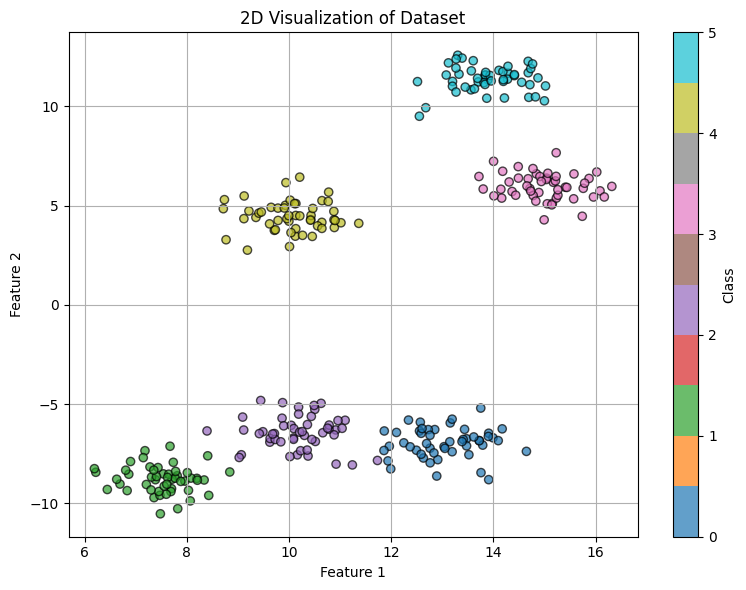

In [19]:

import matplotlib.pyplot as plt
import numpy as np

#TODO visualize the code with matplotlib (fallo figo dai)
train_features = []
train_labels = []
test_features = []

for class_id in range(6):
    # Generate random 2D points for each class centered around different means
    d = (np.random.random() - 0.5) * 5
    m = np.random.random() * 15
    n = np.random.random() * 5
    x = np.random.normal(loc=((class_id+d) * n + m/3,(class_id+d) * n - m), scale=0.7, size=(50, 2))
    train_features.append(x)
    train_labels.extend([class_id] * 50)


train_features = np.vstack(train_features)
train_labels = np.array(train_labels)
# Create scatter plot
plt.figure(figsize=(8, 6))
scatter = plt.scatter(train_features[:, 0], train_features[:, 1], c=train_labels,alpha=0.7, cmap='tab10', edgecolor='k')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('2D Visualization of Dataset')
plt.colorbar(scatter, label='Class')
plt.grid(True)
plt.tight_layout()
plt.show()



answer: Come vediamo le N classi formano N cluster abbastanza be identificabili, ma non linearmente separabili, tuttavia questo non ci preoccupa grazie all'utilizzo delle NN, possiamo anche vedere che i dati di test seguono anche essi una distribuzione simile, il che significa che dovremmo essere in grado di creare una NN in grado di ottenere un accuraci buona per la classificazione di essi.


b: design a neural network using pytorch to correctly assign labels


In [ ]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=1,out_channels=6, kernel_size=(5, 5),stride=1,padding='same',bias=True)
        self.pool = nn.MaxPool2d(2,2)
        self.conv2 = nn.Conv2d(in_channels=6,out_channels=16, kernel_size=(5, 5),stride=1,padding='same',bias=True)
        self.conv3 = nn.Conv2d(in_channels=16,out_channels=32, kernel_size=(5, 5),stride=1,padding='same',bias=True)
        #self.conv4 = nn.Conv2d(in_channels=32,out_channels=64, kernel_size=(5, 5),stride=1,padding='same',bias=True)
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(288, 256,bias=True),
            nn.ReLU(inplace=True),
            nn.Linear(256, 128,bias=True),
            nn.ReLU(inplace=True),
            nn.Linear(128, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 32),
            nn.ReLU(inplace=True),
            nn.Linear(32, 10),
        )

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.pool(torch.relu(self.conv3(x)))
        #x = self.pool(torch.relu(self.conv4(x)))
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

#summary(model, input_size=(1, 28, 28), device=device)

loss_fn = nn.CrossEntropyLoss()
#optimizer = torch.optim.SGD(model.parameters(),lr=1e-2)  # Let's use stocastic gradient descent (We will talk about it in the coming weeks)
optimizer = torch.optim.Adam(model.parameters(),lr= 0.0005,weight_decay=0.0002)  # Let's use stocastic gradient descent (We will talk about it in the coming weeks)

#NN di partenza dall'exercise 3, smanetta e ottimizza

In [ ]:
#train_dataloader = DataLoader(training_data, batch_size=batch_size) da capire con piu visibilita
#test_dataloader = DataLoader(test_data, batch_size=batch_size)

def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    total_loss, correct = 0, 0  # Track the total loss for the epoch

    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)
        total_loss += loss.item()  # Accumulate loss

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        # Calculate accuracy
        correct += (pred.argmax(1) == y).type(torch.float).sum().item()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
    avg_loss = total_loss / len(dataloader)  # Calculate average loss for the epoch
    avg_accuracy = correct / size

    print(f"Train loss: {avg_loss:>7f}, Accuracy: {(100*avg_accuracy):>0.1f}%")

    return (avg_loss ,avg_accuracy) # Store the average loss and accuracy for the epoch

epochs = 25
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    #TODO qui sotto viene usato il test, ma forse devo fare cross validation dividendo il training set, perche non ho lable per il test ??
    test(test_dataloader, model, loss_fn)
print("Done!")

- Describe your network:
    - My NN is a CNN with the following layers:
        - Conv layer x
        - Max pool layer y
        - MLP after that with the following layers interlached by ReLu
            - (512x256)
            - (256xN) where N is the number of classes
        - A softmax at the end to do classification using the CrossEntropy loss (check that this is the correct one)

- Describe your training strategy

    I used the Adam optimizer with a learning rato of Lr found by trying multiple values and a weight_decay of Wd to regularize and reduce overfitting
    I then used a batch size of Bs and trained until the Test_loss (or Validation) didn't improve for 10 epochs in a row and saved the parameters of the best performing model

- Describe your results and discuss the observed performance

   I achived a train accuracy of TrA and a test accuracy of TsA therefore meaning that my model is not biased and achives a preatty high accuracy

- Visualize network performance similar to:

    #---------------------------------------------------------#

    model= #trained pytorch network

    import numpy as np /
    import matplotlib.pyplot as plt /
    model.cpu() /
    x,y=np.meshgrid(np.linspace(-1,1,30),np.linspace(-1,1,30)) /
    xy=np.concatenate((x.reshape(-1,1),y.reshape(-1,1)),axis=1) /
    z=model(torch.tensor(xy).float()).detach().numpy() /
    z=np.argmax(z,1).reshape(30,30) /
    plt.contourf(x,y,z) /
    plt.scatter(testX[:,0],testX[:,1],c=testLabels) /

    #---------------------------------------------------------#

In [ ]:
# TODO visualize like tha